# k-nearest neighbors classification applied to the iris data

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn import datasets
from ipywidgets import interact, IntSlider

The k-nearest neighbors classifier assigns to a point the most frequent class among its $k$ closest training observations. It makes no assumption about the shape of the classes; the only choice is $k$.

We use the first two features of the iris data, to be able to draw the classifier.

In [2]:
# import some data to play with
iris = datasets.load_iris()
X = iris.data[:, :2]  # we only take the first two features.
Y = iris.target

species = [name.capitalize() for name in iris.target_names]
class_colors = ['#0072B2', '#E69F00', '#009E73']

In [3]:
# Grid to plot the decision regions: we will assign a class to each
# point in the mesh [x_min, x_max]x[y_min, y_max].
x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5
y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5
h = .02  # step size in the mesh
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

def plot_regions(ax, k, legend=True):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X, Y)
    Z = knn.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5, 2.5], colors=class_colors, alpha=0.18)
    ax.contour(xx, yy, Z, levels=[0.5, 1.5], colors='#333333', linewidths=0.8)
    for c in range(3):
        ax.plot(X[Y == c, 0], X[Y == c, 1], 'o', color=class_colors[c], markersize=7, markeredgecolor='white',
                markeredgewidth=0.6, label=species[c])
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel(iris.feature_names[0].capitalize())
    ax.set_ylabel(iris.feature_names[1].capitalize())
    ax.set_title(f'k = {k}, training accuracy = {100*knn.score(X, Y):.0f}%')
    if legend:
        ax.legend(loc='upper right', framealpha=1, edgecolor='none')

## One neighbor

With $k = 1$ each point is classified as its closest observation. The regions have islands around single flowers: the classifier follows the noise.

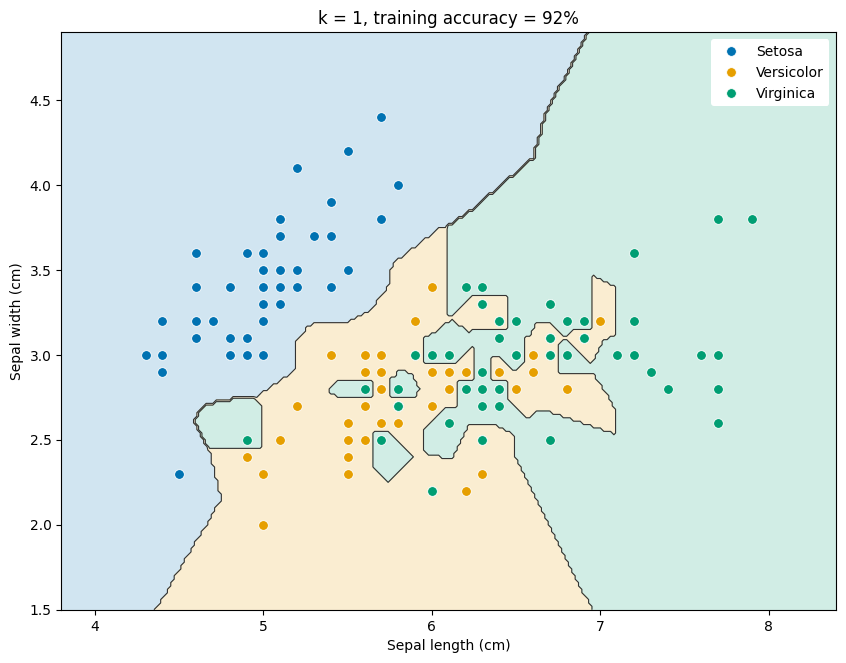

In [4]:
fig, ax = plt.subplots(figsize=(10, 7.5))
plot_regions(ax, 1)

The training accuracy is not 100% only because there are flowers of different species with exactly the same two measurements.

## Choose optimal k

We estimate the accuracy with 5-fold cross-validation, for $k$ between 1 and 30.

In [5]:
k_range = range(1, 31)
k_scores = []
train_scores = []
# use iteration to calculate different k in models, then return the average accuracy based on the cross validation
for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X, Y, cv=5)
    k_scores.append(scores.mean())
    train_scores.append(knn.fit(X, Y).score(X, Y))

k_star = np.where(k_scores == max(k_scores))[0][0]+1
print('k_star:', k_star)

k_star: 17


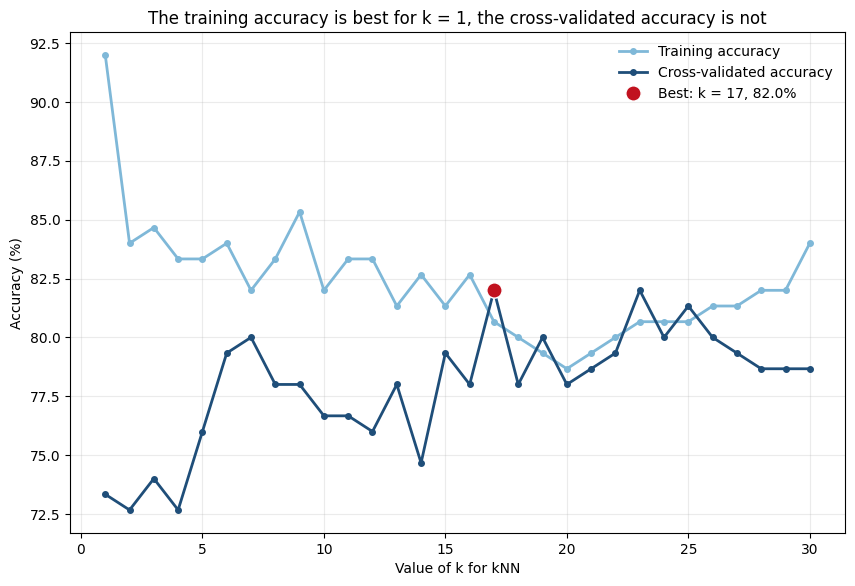

In [6]:
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.plot(k_range, 100*np.array(train_scores), 'o-', color='#7fb8d8', lw=2, markersize=4, label='Training accuracy')
ax.plot(k_range, 100*np.array(k_scores), 'o-', color='#1f4e79', lw=2, markersize=4, label='Cross-validated accuracy')
ax.plot(k_star, 100*max(k_scores), 'o', color='#c1121f', markersize=11, markeredgecolor='white', markeredgewidth=1,
        label=f'Best: k = {k_star}, {100*max(k_scores):.1f}%')
ax.set_xlabel('Value of k for kNN')
ax.set_ylabel('Accuracy (%)')
ax.set_title('The training accuracy is best for k = 1, the cross-validated accuracy is not')
ax.legend(loc='upper right', frameon=False)
ax.grid(True, alpha=0.25)

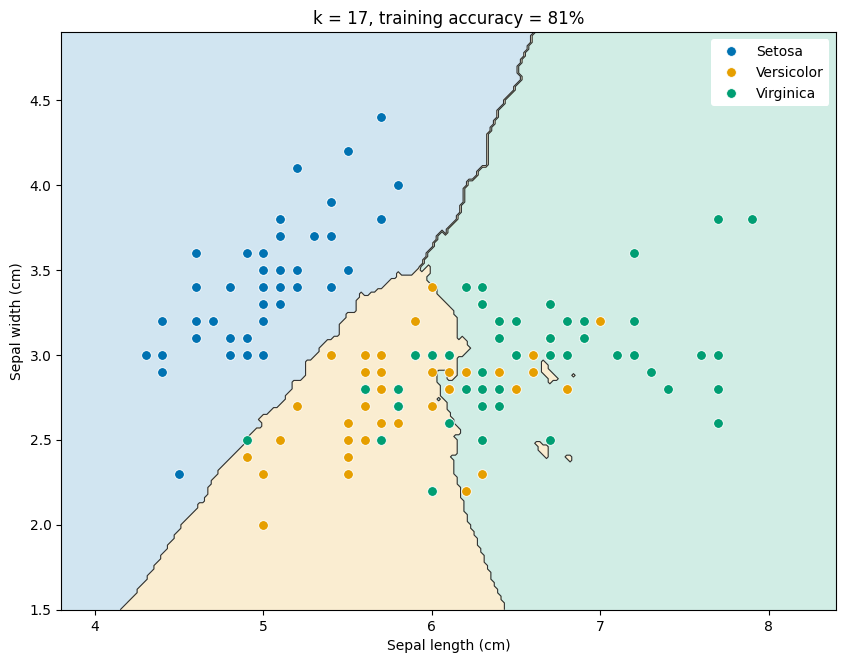

In [7]:
fig, ax = plt.subplots(figsize=(10, 7.5))
plot_regions(ax, k_star)

## The effect of k

A small $k$ gives a flexible and noisy classifier, a large $k$ a smooth one that can miss the shape of the classes. Move the slider to change $k$ (this cell needs a running kernel).

In [8]:
def interactive_knn(k):
    fig, ax = plt.subplots(figsize=(10, 7.5))
    plot_regions(ax, k)
    plt.show()

interact(interactive_knn, k=IntSlider(value=k_star, min=1, max=100, description='k'));

interactive(children=(IntSlider(value=17, description='k', min=1), Output()), _dom_classes=('widget-interact',…

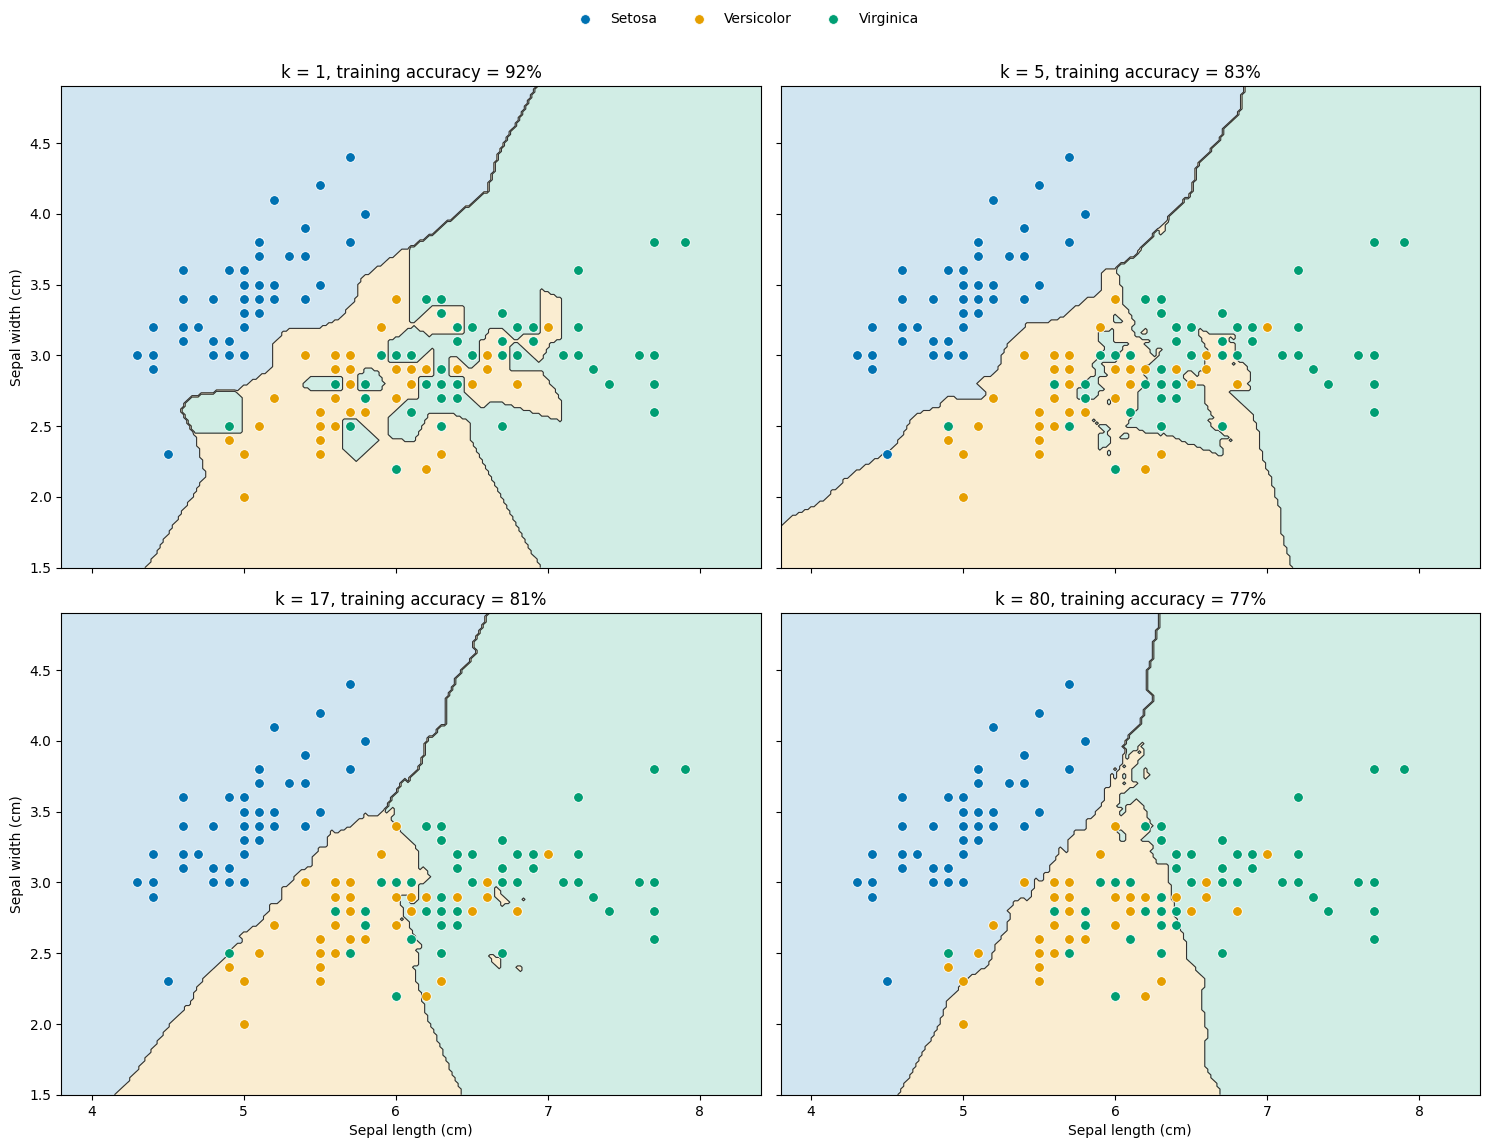

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11.5), sharex=True, sharey=True)
for ax, k in zip(axes.ravel(), [1, 5, k_star, 80]):
    plot_regions(ax, k, legend=False)
for ax in axes[0]:
    ax.set_xlabel('')
for ax in axes[:, 1]:
    ax.set_ylabel('')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.96))